In [1]:
import re
from pathlib import Path
import nibabel as nib
import numpy as np
import pandas as pd
import rsatoolbox
import matplotlib.pyplot as plt
import json

In [2]:
config = json.load(open("probing_rsa_fasting_social_isolation/config.json"))

ROI_DIR = Path("probing_rsa_fasting_social_isolation/masks")
FIRST_LEVEL_DIR = Path(f"{config['data_dir']}/ds003242-1.0.0/derivatives/first_level_nipype")
SECOND_LEVEL_DIR = Path(f"{config['data_dir']}/ds003242-1.0.0/derivatives/second_level_nipype")

OUT_DIR = Path(
    "probing_rsa_fasting_social_isolation/results/rdms"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
ROI_COVERAGE_THRESHOLD = 0.95

# Lets not run a crossvalidated analysis with fewer than two independent runs
MIN_COMMON_RUNS = 2

# Exclude extremely tiny masks even if their proportional coverage is high.
MIN_VOXELS_ROI = 5

# If True, subtract each pattern's voxel mean before calculating distances.
REMOVE_PATTERN_MEAN = False

In [4]:
SESSION_MAP = {
    "b": "baseline",
    "f": "fasting",
    "s": "isolation",
}

STIMULI = {
    "food": "con_2_food_gt_rest_cope.nii.gz",
    "social": "con_4_social_gt_rest_cope.nii.gz",
    "flowers": "con_6_control_gt_rest_cope.nii.gz",
}

CONDITION_ORDER = [
    "food_baseline",
    "social_baseline",
    "flowers_baseline",
    "food_fasting",
    "social_fasting",
    "flowers_fasting",
    "food_isolation",
    "social_isolation",
    "flowers_isolation",
]

In [5]:
def split_subject_session(subject_session: str) -> tuple[str, str]:
    """
    SAXSISO01b -> ('SAXSISO01', 'b')
    """
    return subject_session[:-1], subject_session[-1]


def load_3d(path: Path) -> nib.Nifti1Image:
    img = nib.load(str(path))
    if img.ndim != 3:
        raise ValueError(f"Expected 3D image, found {img.ndim}D: {path}")
    return img


def same_grid(reference_img: nib.spatialimages.SpatialImage,
              test_img: nib.spatialimages.SpatialImage,
              atol: float = 1e-4) -> bool:
    return (
        reference_img.shape[:3] == test_img.shape[:3]
        and np.allclose(reference_img.affine, test_img.affine, atol=atol)
    )


def require_same_grid(reference_img, test_img, test_path: Path) -> None:
    if not same_grid(reference_img, test_img):
        raise ValueError(
            "\nGrid mismatch detected.\n"
            f"Reference shape: {reference_img.shape[:3]}\n"
            f"Test shape:      {test_img.shape[:3]}\n"
            f"Problem image:   {test_path}\n\n"
            "All cope maps, residuals, ROI masks, and run masks must be in "
            "the same MNI grid before extracting RSA patterns. Resample the "
            "data images with continuous interpolation and masks with nearest "
            "neighbor interpolation, then rerun."
        )


def get_mask_data(path: Path, reference_img: nib.Nifti1Image) -> np.ndarray:
    img = load_3d(path)
    require_same_grid(reference_img, img, path)
    return img.get_fdata() > 0


def run_dir_for(subject_session: str, run_label: str) -> Path:
    return FIRST_LEVEL_DIR / f"{subject_session}" / "CIC" / "model" /run_label


def available_run_labels(subject_session: str) -> list[str]:
    """
    Finds run1, run2, ... folders, retaining only folders with all three
    stimulus-vs-rest cope images.
    """
    cic_dir = FIRST_LEVEL_DIR / f"{subject_session}" / "CIC" / "model"

    if not cic_dir.exists():
        print(f"Directory does not exist: {cic_dir}")
        return []

    run_dirs = [
        p for p in cic_dir.iterdir()
        if p.is_dir() and re.fullmatch(r"run\d+", p.name)
    ]

    def run_number(path: Path) -> int:
        return int(re.search(r"\d+", path.name).group())

    run_dirs = sorted(run_dirs, key=run_number)

    complete_runs = []
    for run_dir in run_dirs:
        has_all_copes = all((run_dir / cope_name).exists()
                            for cope_name in STIMULI.values())
        if has_all_copes:
            complete_runs.append(run_dir.name)
        else:
            print(
                f"Skipping incomplete run: {run_dir}. "
                "At least one required cope is missing."
            )

    return complete_runs


def session_run_intersection_mask_path(subject_session: str) -> Path:
    """
    This is existing per-session intersection across that session's runs we saved after 1.5 level analysis.
    """
    folder = f"{subject_session}"
    return (
        SECOND_LEVEL_DIR
        / folder
        / "CIC"
        / "masks"
        / f"{folder}_CIC_run-intersection_mask.nii.gz"
    )


def build_joint_subject_mask(subject, roi_name):
    """
    ROI ∩ baseline run-intersection ∩ fasting run-intersection ∩ isolation run-intersection
    """
    session_masks = {}

    for session_letter in SESSION_MAP:
        subject_session = f"{subject}{session_letter}"
        mask_path = session_run_intersection_mask_path(subject_session)

        if not mask_path.exists():
            raise FileNotFoundError(f"Missing run-intersection mask: {mask_path}")

        mask_img = load_3d(mask_path)
    
        session_masks[session_letter] = mask_img.get_fdata() > 0

    joint_run_mask = np.logical_and.reduce(list(session_masks.values()))

    roi_path = ROI_DIR / f"{roi_name}.gz"
    if not roi_path.exists():
        raise FileNotFoundError(f"ROI mask not found: {roi_path}")

    roi_mask = get_mask_data(roi_path, mask_img)
    if roi_mask.sum() == 0:
        raise ValueError(f"ROI is empty: {roi_name}")

    final_mask = roi_mask & joint_run_mask
    joint_coverage = final_mask.sum() / roi_mask.sum()

    return mask_img, final_mask, float(joint_coverage)


def get_common_runs(subject):
    runs_by_session = {}
    for session_letter in SESSION_MAP:
        subject_session = f"{subject}{session_letter}"
        runs_by_session[session_letter] = set(available_run_labels(subject_session))

    common_runs = sorted(
        set.intersection(*runs_by_session.values()),
        key=lambda x: int(re.search(r"\d+", x).group()),
    )
    return common_runs

In [6]:
def extract_patterns_and_residuals(subject, analysis_mask, reference_img, common_runs):
    """
    Returns:
        measurements: (n_runs * n_conditions, n_voxels)  -- one row per run x condition
        condition_labels: (n_runs * n_conditions,)
        run_labels: (n_runs * n_conditions,)
    """
    rows_measurements = []
    rows_condition = []
    rows_run = []

    for run_label in common_runs:
        for session_letter, session_name in SESSION_MAP.items():
            subject_session = f"{subject}{session_letter}"
            run_dir = run_dir_for(subject_session, run_label)

            for stimulus_name, cope_filename in STIMULI.items():
                cope_path = run_dir / cope_filename
                if not cope_path.exists():
                    raise FileNotFoundError(f"Missing cope: {cope_path}")

                cope_img = load_3d(cope_path)
                require_same_grid(reference_img, cope_img, cope_path)
                cope_values = cope_img.get_fdata(dtype=np.float32)[analysis_mask]

                if not np.all(np.isfinite(cope_values)):
                    raise ValueError(f"Non-finite cope values: {cope_path}")

                condition_name = f"{stimulus_name}_{session_name}"

                rows_measurements.append(cope_values)
                rows_condition.append(condition_name)
                rows_run.append(run_label)
                # Same residual time series is shared by all 3 stimuli of this
                # session/run (they come from the same first-level GLM run).


    measurements = np.stack(rows_measurements, axis=0)
    condition_labels = np.array(rows_condition)
    run_labels = np.array(rows_run)

    return measurements, condition_labels, run_labels


In [7]:
def compute_subject_roi_rdm(subject, roi_name):

    reference_img, analysis_mask, joint_coverage = build_joint_subject_mask(subject, roi_name)
    n_voxels = int(analysis_mask.sum())

    if joint_coverage < ROI_COVERAGE_THRESHOLD:
        raise ValueError(f"joint coverage {joint_coverage:.3f} < {ROI_COVERAGE_THRESHOLD}")
    if n_voxels < MIN_VOXELS_ROI:
        raise ValueError(f"fewer than {MIN_VOXELS_ROI} voxels")

    common_runs = get_common_runs(subject)
    if len(common_runs) < MIN_COMMON_RUNS:
        raise ValueError(f"only {len(common_runs)} common runs")

    measurements, condition_labels, run_labels = extract_patterns_and_residuals(
        subject, analysis_mask, reference_img, common_runs
    )

    dataset = rsatoolbox.data.Dataset(
        measurements=measurements,
        obs_descriptors={"condition": condition_labels, "run": run_labels},
    )

    rdm_obj = rsatoolbox.rdm.calc_rdm(
        dataset,
        method="crossnobis",
        descriptor="condition",
        cv_descriptor="run",
        noise=None,
    )

    # Reorder to CONDITION_ORDER (calc_rdm sorts labels
    # alphabetically by default, not in intended order)
    rdm_obj.reorder(np.array([
        list(rdm_obj.pattern_descriptors["condition"]).index(c)
        for c in CONDITION_ORDER
    ]))

    rdm_matrix = rdm_obj.get_matrices()[0]

    return {
        "subject": subject,
        "roi": roi_name,
        "rdm_object": rdm_obj,
        "rdm_matrix": rdm_matrix,
        "n_voxels": n_voxels,
        "joint_coverage": joint_coverage,
        "common_runs": common_runs,
    }

In [8]:
roi_names = [f.stem for f in ROI_DIR.glob("*.nii.gz")]
roi_names

['Frontal Pole.nii',
 'Insular Cortex.nii',
 'Superior Frontal Gyrus.nii',
 'Middle Frontal Gyrus.nii',
 'Inferior Frontal Gyrus, pars triangularis.nii',
 'Inferior Frontal Gyrus, pars opercularis.nii',
 'Precentral Gyrus.nii',
 'Temporal Pole.nii',
 'Superior Temporal Gyrus, anterior division.nii',
 'Superior Temporal Gyrus, posterior division.nii',
 'Middle Temporal Gyrus, anterior division.nii',
 'Middle Temporal Gyrus, posterior division.nii',
 'Middle Temporal Gyrus, temporooccipital part.nii',
 'Inferior Temporal Gyrus, anterior division.nii',
 'Inferior Temporal Gyrus, posterior division.nii',
 'Inferior Temporal Gyrus, temporooccipital part.nii',
 'Postcentral Gyrus.nii',
 'Superior Parietal Lobule.nii',
 'Supramarginal Gyrus, anterior division.nii',
 'Supramarginal Gyrus, posterior division.nii',
 'Angular Gyrus.nii',
 'Lateral Occipital Cortex, superior division.nii',
 'Lateral Occipital Cortex, inferior division.nii',
 'Intracalcarine Cortex.nii',
 'Frontal Medial Cortex.nii

In [9]:
len(roi_names)

74

In [10]:
subjects = sorted(set(f.stem[:-1] for f in Path(FIRST_LEVEL_DIR).glob("sub-*")))
subjects

['sub-SAXSISO01',
 'sub-SAXSISO02',
 'sub-SAXSISO03',
 'sub-SAXSISO04',
 'sub-SAXSISO08',
 'sub-SAXSISO09',
 'sub-SAXSISO10',
 'sub-SAXSISO11',
 'sub-SAXSISO12',
 'sub-SAXSISO13',
 'sub-SAXSISO14',
 'sub-SAXSISO15',
 'sub-SAXSISO17',
 'sub-SAXSISO18',
 'sub-SAXSISO19',
 'sub-SAXSISO21',
 'sub-SAXSISO22',
 'sub-SAXSISO24',
 'sub-SAXSISO26',
 'sub-SAXSISO27',
 'sub-SAXSISO28',
 'sub-SAXSISO30',
 'sub-SAXSISO32',
 'sub-SAXSISO33',
 'sub-SAXSISO34',
 'sub-SAXSISO35',
 'sub-SAXSISO36',
 'sub-SAXSISO38',
 'sub-SAXSISO39',
 'sub-SAXSISO40',
 'sub-SAXSISO41',
 'sub-SAXSISO42']

In [11]:
len(subjects)

32

In [12]:
n_sub, n_roi, n = len(subjects), len(roi_names), len(CONDITION_ORDER)
rdms = np.zeros((n_sub, n_roi, n, n))

rows = []

for i, subject in enumerate(subjects):
    for j, roi_name in enumerate(roi_names):
        print(f"Processing subject={subject}, roi={roi_name}")
        try:
            result = compute_subject_roi_rdm(subject, roi_name)
            rdms[i, j] = result["rdm_matrix"]

            rows.append({
                "subject": subject,
                "roi": roi_name,
                "included": True,
                "exclusion_reason": None,
                "n_voxels": result["n_voxels"],
                "joint_roi_coverage": result["joint_coverage"],
                "n_common_runs": len(result["common_runs"]),
            })
        except Exception as e:
            print(f"Failed processing subject={subject}, roi={roi_name}: {e}")
            rows.append({
                "subject": subject,
                "roi": roi_name,
                "included": False,
                "exclusion_reason": str(e),
                "n_voxels": None,
                "joint_roi_coverage": None,
                "n_common_runs": None,
            })

np.savez_compressed(
    OUT_DIR / "crossnobis_rdms.npz",
    rdms=rdms,
    subjects=np.array(subjects),
    rois=np.array(roi_names),
    conditions=np.array(CONDITION_ORDER),
)

Processing subject=sub-SAXSISO01, roi=Frontal Pole.nii
Failed processing subject=sub-SAXSISO01, roi=Frontal Pole.nii: joint coverage 0.822 < 0.95
Processing subject=sub-SAXSISO01, roi=Insular Cortex.nii
Processing subject=sub-SAXSISO01, roi=Superior Frontal Gyrus.nii
Failed processing subject=sub-SAXSISO01, roi=Superior Frontal Gyrus.nii: joint coverage 0.938 < 0.95
Processing subject=sub-SAXSISO01, roi=Middle Frontal Gyrus.nii
Processing subject=sub-SAXSISO01, roi=Inferior Frontal Gyrus, pars triangularis.nii
Failed processing subject=sub-SAXSISO01, roi=Inferior Frontal Gyrus, pars triangularis.nii: joint coverage 0.947 < 0.95
Processing subject=sub-SAXSISO01, roi=Inferior Frontal Gyrus, pars opercularis.nii
Processing subject=sub-SAXSISO01, roi=Precentral Gyrus.nii
Failed processing subject=sub-SAXSISO01, roi=Precentral Gyrus.nii: joint coverage 0.939 < 0.95
Processing subject=sub-SAXSISO01, roi=Temporal Pole.nii
Failed processing subject=sub-SAXSISO01, roi=Temporal Pole.nii: joint c

/local/anpa/LAB_IMMERSION/venv_lab_immersion/lib/python3.10/site-packages/rsatoolbox/data/computations.py:36: RuntimeWarning: invalid value encountered in multiply
  average = np.nan * np.empty(


Processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, anterior division.nii
Failed processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, anterior division.nii: joint coverage 0.828 < 0.95
Processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, posterior division.nii
Failed processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, posterior division.nii: joint coverage 0.865 < 0.95
Processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, temporooccipital part.nii
Failed processing subject=sub-SAXSISO01, roi=Middle Temporal Gyrus, temporooccipital part.nii: joint coverage 0.856 < 0.95
Processing subject=sub-SAXSISO01, roi=Inferior Temporal Gyrus, anterior division.nii
Failed processing subject=sub-SAXSISO01, roi=Inferior Temporal Gyrus, anterior division.nii: joint coverage 0.397 < 0.95
Processing subject=sub-SAXSISO01, roi=Inferior Temporal Gyrus, posterior division.nii
Failed processing subject=sub-SAXSISO01, roi=Inferior Temporal Gyrus, posterior division.nii

In [13]:
rdms.shape

(32, 74, 9, 9)

In [ ]:
df = pd.DataFrame(rows)
df

,subject,roi,included,exclusion_reason,n_voxels,joint_roi_coverage,n_common_runs
0,sub-SAXSISO01,Frontal Pole.nii,False,joint coverage 0.822 < 0.95,NaN,NaN,NaN
1,sub-SAXSISO01,Insular Cortex.nii,True,None,977.0,1.000000,4.0
2,sub-SAXSISO01,Superior Frontal Gyrus.nii,False,joint coverage 0.938 < 0.95,NaN,NaN,NaN
3,sub-SAXSISO01,Middle Frontal Gyrus.nii,True,None,2224.0,0.982332,4.0
4,sub-SAXSISO01,"Inferior Frontal Gyrus, pars triangularis.nii",False,joint coverage 0.947 < 0.95,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2363,sub-SAXSISO42,HN.nii,False,fewer than 5 voxels,NaN,NaN,NaN
2364,sub-SAXSISO42,HTH.nii,True,None,133.0,0.963768,6.0
2365,sub-SAXSISO42,MN.nii,True,None,11.0,1.000000,6.0
2366,sub-SAXSISO42,STH.nii,True,None,19.0,1.000000,6.0


In [17]:
df.query('included')

,subject,roi,included,exclusion_reason,n_voxels,joint_roi_coverage,n_common_runs
1,sub-SAXSISO01,Insular Cortex.nii,True,None,977.0,1.000000,4.0
3,sub-SAXSISO01,Middle Frontal Gyrus.nii,True,None,2224.0,0.982332,4.0
5,sub-SAXSISO01,"Inferior Frontal Gyrus, pars opercularis.nii",True,None,622.0,0.970359,4.0
8,sub-SAXSISO01,"Superior Temporal Gyrus, anterior division.nii",True,None,231.0,0.978814,4.0
9,sub-SAXSISO01,"Superior Temporal Gyrus, posterior division.nii",True,None,756.0,0.985658,4.0
...,...,...,...,...,...,...,...
2362,sub-SAXSISO42,VeP.nii,True,None,10.0,1.000000,6.0
2364,sub-SAXSISO42,HTH.nii,True,None,133.0,0.963768,6.0
2365,sub-SAXSISO42,MN.nii,True,None,11.0,1.000000,6.0
2366,sub-SAXSISO42,STH.nii,True,None,19.0,1.000000,6.0


In [18]:
df.query('included').roi.value_counts()

roi
Insular Cortex.nii                                                         32
Superior Parietal Lobule.nii                                               32
Angular Gyrus.nii                                                          32
Intracalcarine Cortex.nii                                                  32
Supramarginal Gyrus, posterior division.nii                                32
Precuneous Cortex.nii                                                      32
Cingulate Gyrus, posterior division.nii                                    32
Cingulate Gyrus, anterior division.nii                                     32
Paracingulate Gyrus.nii                                                    32
Juxtapositional Lobule Cortex (formerly Supplementary Motor Cortex).nii    32
Parietal Opercular Cortex.nii                                              32
Occipital Fusiform Gyrus.nii                                               32
Frontal Opercular Cortex.nii                                

In [20]:
d = np.load(OUT_DIR / "crossnobis_rdms.npz")
d

NpzFile 'probing_rsa_fasting_social_isolation/results/rdms/crossnobis_rdms.npz' with keys: rdms, subjects, rois, conditions

In [28]:
rdm = d["rdms"][list(d["subjects"]).index("sub-SAXSISO01"), list(d["rois"]).index("Pu.nii")]
rdm

array([[ 0.        ,  0.0501884 , -0.00102678,  0.05363569,  0.05038453,
         0.20948757,  0.32573402,  0.12635759,  0.15296879],
       [ 0.0501884 ,  0.        ,  0.01725196,  0.01909231,  0.00240232,
         0.05739799,  0.15682174,  0.02130025,  0.07626607],
       [-0.00102678,  0.01725196,  0.        ,  0.0202971 , -0.02474171,
         0.04477293,  0.24186863,  0.05753067,  0.101157  ],
       [ 0.05363569,  0.01909231,  0.0202971 ,  0.        ,  0.01250485,
         0.00589674,  0.04995241, -0.0402687 ,  0.02253497],
       [ 0.05038453,  0.00240232, -0.02474171,  0.01250485,  0.        ,
         0.0277144 ,  0.10195953, -0.05963177,  0.02111574],
       [ 0.20948757,  0.05739799,  0.04477293,  0.00589674,  0.0277144 ,
         0.        , -0.00731955, -0.1106239 , -0.0413376 ],
       [ 0.32573402,  0.15682174,  0.24186863,  0.04995241,  0.10195953,
        -0.00731955,  0.        ,  0.06033544,  0.01480729],
       [ 0.12635759,  0.02130025,  0.05753067, -0.0402687 , -0

In [30]:
def plot_rdm(rdm_matrix, subject, roi_name):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(rdm_matrix, cmap="viridis")
    ax.set_xticks(range(len(CONDITION_ORDER)))
    ax.set_yticks(range(len(CONDITION_ORDER)))
    ax.set_xticklabels(CONDITION_ORDER, rotation=90)
    ax.set_yticklabels(CONDITION_ORDER)
    ax.set_title(f"sub-{subject} | {roi_name}")
    fig.colorbar(im, ax=ax, label="crossnobis distance")
    fig.tight_layout()

    plt.show()
    plt.close(fig)

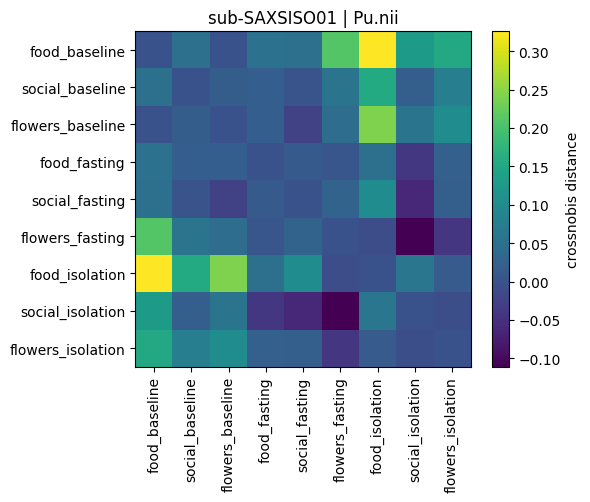

In [31]:
plot_rdm(rdm, "SAXSISO01", "Pu.nii")

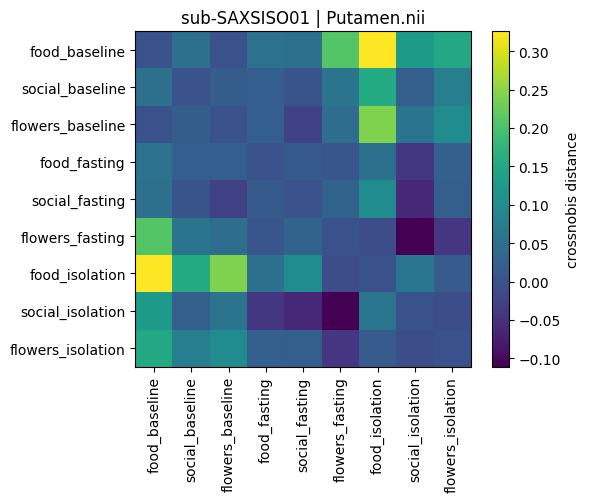

In [32]:
plot_rdm(rdm, "SAXSISO01", "Putamen.nii")